# Лекция 3. Введение в машинное обучение и sklearn

**Дисциплина:** Анализ данных в Python  
**Тема:** Постановка задач ML, переобучение, кросс-валидация, Pipeline

В этом ноутбуке:
- Что такое машинное обучение
- Типы задач: с учителем, без учителя, с подкреплением
- Переобучение и недообучение
- Разделение данных (train / validation / test)
- Кросс-валидация
- Библиотека sklearn, Pipeline, ColumnTransformer

In [24]:
# Импорт библиотек
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

sns.set_style('whitegrid')

## 1. Типы машинного обучения

- **С учителем (supervised)** — есть размеченные данные. Делится на **регрессию** и **классификацию**.
- **Без учителя (unsupervised)** — разметки нет. Задачи: кластеризация, снижение размерности, поиск аномалий.
- **С подкреплением (reinforcement)** — агент учится, взаимодействуя со средой.

In [25]:
# Загрузим датасет Breast Cancer (для бинарной классификации)
data = load_breast_cancer()
X = data.data
y = data.target

print('Размер X:', X.shape)
print('Размер y:', y.shape)
print('Классы:', np.unique(y))
print('Названия признаков (первые 5):', data.feature_names[:5])

Размер X: (569, 30)
Размер y: (569,)
Классы: [0 1]
Названия признаков (первые 5): ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness']


## 2. Разделение данных

Обычно делят в пропорции **60/20/20**:
- **train** — обучение модели;
- **validation** — настройка гиперпараметров;
- **test** — финальная оценка (один раз).

In [26]:
# Разделение: сначала отделим test (20%), потом из оставшегося — validation (20%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

print('Train:', X_train.shape[0])
print('Val:  ', X_val.shape[0])
print('Test: ', X_test.shape[0])

# Проверим стратификацию (доли классов сохранены)
print('\nДоля класса 1:')
print('  Train:', y_train.mean().round(3))
print('  Val:  ', y_val.mean().round(3))
print('  Test: ', y_test.mean().round(3))

Train: 341
Val:   114
Test:  114

Доля класса 1:
  Train: 0.628
  Val:   0.623
  Test:  0.632


## 3. Первая модель — логистическая регрессия

Масштабирование обязательно: логистическая регрессия чувствительна к масштабу признаков.

In [27]:
# Модель с масштабированием (через Pipeline)
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000))
])

pipe.fit(X_train, y_train)

# Оценка на валидации
y_val_pred = pipe.predict(X_val)
print('Accuracy на валидации:', accuracy_score(y_val, y_val_pred))
print('F1 на валидации:', f1_score(y_val, y_val_pred))

Accuracy на валидации: 0.9912280701754386
F1 на валидации: 0.993006993006993


In [28]:
# Сравним с моделью БЕЗ масштабирования
pipe_no_scale = Pipeline([
    ('clf', LogisticRegression(max_iter=1000))
])

pipe_no_scale.fit(X_train, y_train)
y_val_pred_ns = pipe_no_scale.predict(X_val)

print('Без масштабирования:')
print('Accuracy:', accuracy_score(y_val, y_val_pred_ns))
print('F1:', f1_score(y_val, y_val_pred_ns))

Без масштабирования:
Accuracy: 0.9385964912280702
F1: 0.951048951048951


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 4. Кросс-валидация

Кросс-валидация даёт более надёжную оценку, чем одно разделение.  
Данные делятся на **k фолдов**: модель обучается на k-1 и оценивается на 1, повторяем k раз.

In [29]:
# 5-fold кросс-валидация для логистической регрессии
model = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000))
])

scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1')

print('F1 по фолдам:', scores.round(4))
print(f'Среднее F1: {scores.mean():.4f}')
print(f'Стд. отклонение: {scores.std():.4f}')

F1 по фолдам: [0.9885 0.9773 0.9882 0.9773 0.9767]
Среднее F1: 0.9816
Стд. отклонение: 0.0055


## 5. Pipeline и ColumnTransformer

**Pipeline** — объединяет шаги обработки и модель в один объект.  
**ColumnTransformer** — применяет разные преобразования к разным столбцам.

Комплексный пример: Pipeline + ColumnTransformer + Titanic


ШАГ 1. Загрузка и подготовка данных

In [30]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

df = sns.load_dataset('titanic').dropna(subset=['age', 'embarked'])

# Выбираем 4 признака: 2 числовых, 2 категориальных
X = df[['age', 'fare', 'sex', 'embarked']]
y = df['survived']

# Разделение на train/test со стратификацией
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Размер train: {X_train.shape[0]}')
print(f'Размер test:  {X_test.shape[0]}')
print(f'Доля выживших в train: {y_train.mean():.3f}')
print(f'Доля выживших в test:  {y_test.mean():.3f}')


Размер train: 569
Размер test:  143
Доля выживших в train: 0.404
Доля выживших в test:  0.406


ШАГ 2. ColumnTransformer: разные преобразования для разных столбцов

In [31]:
numeric_features = ['age', 'fare']
categorical_features = ['sex', 'embarked']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
])

ШАГ 3. Pipeline: предобработка + модель

In [32]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Обучение
model.fit(X_train, y_train)

# Оценка на тестовой выборке
y_pred = model.predict(X_test)
print(f'\nAccuracy на Titanic: {accuracy_score(y_test, y_pred):.4f}')
print(f'F1 на Titanic:       {f1_score(y_test, y_pred):.4f}')


Accuracy на Titanic: 0.7762
F1 на Titanic:       0.7193


ШАГ 4. Кривая обучения — диагностика переобучения

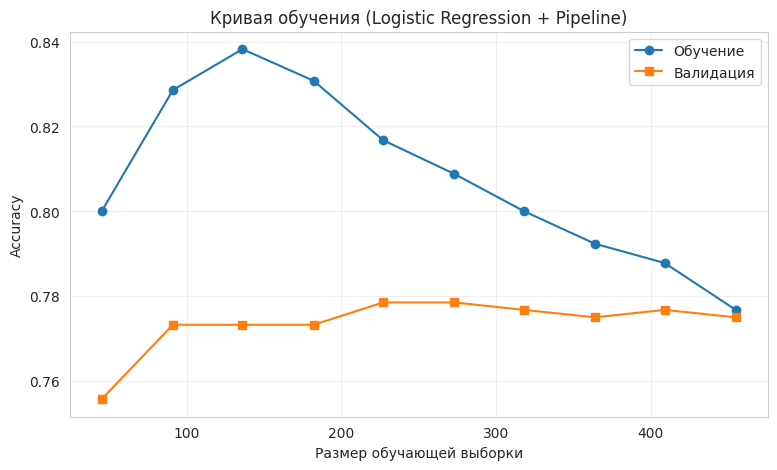

In [33]:

train_sizes, train_scores, val_scores = learning_curve(
    model,                # тот же Pipeline
    X_train, y_train,     # обучающие данные
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1             # используем все ядра CPU
)

# Усреднённые значения по фолдам
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_mean, 'o-', label='Обучение')
plt.plot(train_sizes, val_mean, 's-', label='Валидация')
plt.xlabel('Размер обучающей выборки')
plt.ylabel('Accuracy')
plt.title('Кривая обучения (Logistic Regression + Pipeline)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Кривая обучения — диагностика переобучения

**Кривая обучения** показывает, как качество модели зависит от размера обучающей выборки.  
Если train-качество высокое, а validation — низкое → **переобучение**.

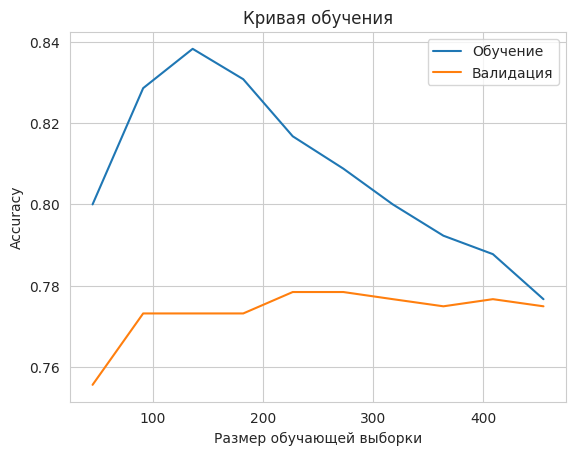

In [34]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    model, X_train, y_train, cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

plt.plot(train_sizes, train_scores.mean(axis=1), label='Обучение')
plt.plot(train_sizes, val_scores.mean(axis=1), label='Валидация')
plt.xlabel('Размер обучающей выборки')
plt.ylabel('Accuracy')
plt.title('Кривая обучения')
plt.legend()
plt.show()

## Выводы по лекции 3

- ML — это не просто применение алгоритма, а целостный процесс.
- Данные делятся на train / validation / test со стратификацией.
- Кросс-валидация даёт более надёжную оценку.
- Pipeline исключает утечку данных и упрощает код.
- ColumnTransformer позволяет применять разные преобразования к разным столбцам.